<a href="https://colab.research.google.com/github/divyayalam/Camouflage/blob/rishikesh-track2/track2_predictionAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

In [3]:
model = keras.models.load_model(
    "/content/drive/MyDrive/best_animal_cnn.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


In [15]:
(_, _), (test_images_full, test_labels_full) = \
    keras.datasets.cifar10.load_data()

In [5]:
ANIMAL_CLASS_IDS = [2, 3, 4, 5, 6, 7]

ANIMAL_NAMES = [
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse"
]

labels = test_labels_full.flatten()

mask = np.isin(labels, ANIMAL_CLASS_IDS)

test_images = test_images_full[mask]
old_labels = labels[mask]

label_map = {
    2: 0,
    3: 1,
    4: 2,
    5: 3,
    6: 4,
    7: 5
}

test_labels = np.array([
    label_map[label] for label in old_labels
])

print(test_images.shape)
print(test_labels.shape)

(6000, 32, 32, 3)
(6000,)


In [6]:
test_images_norm = test_images.astype("float32") / 255.0

print("Normalization complete")

Normalization complete


In [7]:
predictions_prob = model.predict(
    test_images_norm,
    verbose=1
)

predicted_labels = np.argmax(
    predictions_prob,
    axis=1
)

print("Predictions complete!")

188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 80ms/step
Predictions complete!


In [16]:
np.savez_compressed(
    "/content/drive/MyDrive/track2_results.npz",
    predictions_prob=predictions_prob,
    predicted_labels=predicted_labels,
    test_labels=test_labels,
    test_images=test_images
)

print("Track 2 results saved to Drive!")

Track 2 results saved to Drive!


In [17]:
accuracy = np.mean(predicted_labels == test_labels)

print(f"Test accuracy: {accuracy * 100:.2f}%")

Test accuracy: 71.10%


In [18]:
correct_indices = np.where(
    predicted_labels == test_labels
)[0][:5]

incorrect_indices = np.where(
    predicted_labels != test_labels
)[0][:5]

print("Correct indices:", correct_indices)
print("Incorrect indices:", incorrect_indices)

Correct indices: [0 1 2 3 4]
Incorrect indices: [ 5 12 18 19 20]


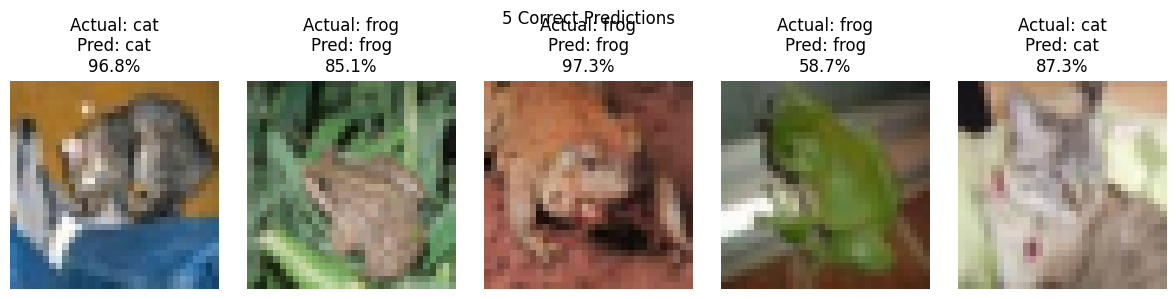

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i, idx in enumerate(correct_indices):
    axes[i].imshow(test_images[idx])

    actual = ANIMAL_NAMES[test_labels[idx]]
    predicted = ANIMAL_NAMES[predicted_labels[idx]]

    confidence = predictions_prob[
        idx,
        predicted_labels[idx]
    ] * 100

    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"{confidence:.1f}%"
    )

    axes[i].axis("off")

plt.suptitle("5 Correct Predictions")
plt.tight_layout()
plt.show()

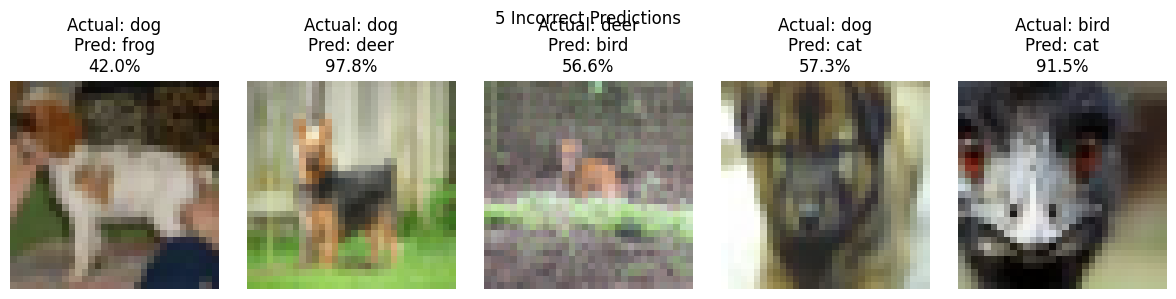

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i, idx in enumerate(incorrect_indices):
    axes[i].imshow(test_images[idx])

    actual = ANIMAL_NAMES[test_labels[idx]]
    predicted = ANIMAL_NAMES[predicted_labels[idx]]

    confidence = predictions_prob[
        idx,
        predicted_labels[idx]
    ] * 100

    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"{confidence:.1f}%"
    )

    axes[i].axis("off")

plt.suptitle("5 Incorrect Predictions")
plt.tight_layout()
plt.show()

Observation:
The model performs well on many clear images, but the incorrect predictions show that it can become confused by low-resolution images, unusual poses, backgrounds, and visually similar textures. Some mistakes have relatively low confidence, suggesting uncertainty, while others are made with very high confidence. For example, a dog was classified as a deer with 97.8% confidence and a bird was classified as a cat with 91.5% confidence. These high-confidence errors suggest that the CNN may sometimes rely on misleading visual features rather than the true object itself.


In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_labels,
    predicted_labels
)

print(cm)

[[675  39  48  22 126  90]
 [ 58 623  46  71 119  83]
 [ 56  47 666   1 138  92]
 [ 42 159  47 484 106 162]
 [ 34  36   5   2 913  10]
 [ 15  19  32   5  24 905]]


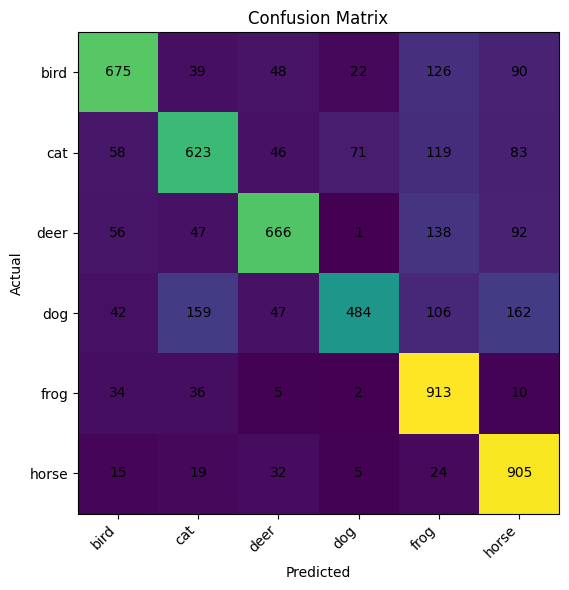

In [22]:
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm)

ax.set_xticks(np.arange(len(ANIMAL_NAMES)))
ax.set_yticks(np.arange(len(ANIMAL_NAMES)))

ax.set_xticklabels(ANIMAL_NAMES)
ax.set_yticklabels(ANIMAL_NAMES)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix")

plt.tight_layout()
plt.show()

In [23]:
from sklearn.metrics import classification_report

print(
    classification_report(
        test_labels,
        predicted_labels,
        target_names=ANIMAL_NAMES
    )
)

              precision    recall  f1-score   support

        bird       0.77      0.68      0.72      1000
         cat       0.67      0.62      0.65      1000
        deer       0.79      0.67      0.72      1000
         dog       0.83      0.48      0.61      1000
        frog       0.64      0.91      0.75      1000
       horse       0.67      0.91      0.77      1000

    accuracy                           0.71      6000
   macro avg       0.73      0.71      0.70      6000
weighted avg       0.73      0.71      0.70      6000



In [24]:
!git clone https://github.com/divyayalam/Camouflage.git
%cd Camouflage
!git fetch origin
!git branch -a

Cloning into 'Camouflage'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (48/48), done.
remote: Total 50 (delta 10), reused 8 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 44.28 MiB | 27.71 MiB/s, done.
Resolving deltas: 100% (10/10), done.
/content/Camouflage
* main
  remotes/origin/Ganesh-Track3
  remotes/origin/HEAD -> origin/main
  remotes/origin/Jay-track1
  remotes/origin/main
  remotes/origin/rishikesh-track2
  remotes/origin/sid-track1
  remotes/origin/tanishka_track2


In [25]:
!git ls-tree -r --name-only origin/Jay-track1

.gitignore
README.md
cifar10_animal_classification-2.ipynb
metrics.py
metrics_demo.ipynb


In [26]:
!git ls-tree -r --name-only origin/sid-track1

.gitignore
README.md
animal_cnn_final.keras
app.py
cifar10-dashboard-test-images.zip
cifar10_animal_classification_2.ipynb
metrics.py
metrics_demo.ipynb
run1_original.zip
run2_mild.zip
run3_stronger.zip
run4_heavy.zip


In [27]:
!git ls-tree -r --name-only origin/tanishka_track2

.gitignore
README.md
Track 2 (Explainability & Analysis).ipynb
metrics.py
metrics_demo.ipynb
shortcut_reliance_experiments.pdf


In [28]:
!git checkout origin/sid-track1 -- run1_original.zip
!git checkout origin/sid-track1 -- run2_mild.zip
!git checkout origin/sid-track1 -- run3_stronger.zip
!git checkout origin/sid-track1 -- run4_heavy.zip

In [29]:
!unzip -l run1_original.zip
!unzip -l run2_mild.zip
!unzip -l run3_stronger.zip
!unzip -l run4_heavy.zip

Archive:  run1_original.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
        0  2026-10-19 21:44   run1_original/
      212  2026-10-19 21:44   __MACOSX/._run1_original
    59823  2026-10-18 16:03   run1_original/sample_images.png
      212  2026-10-18 16:03   __MACOSX/run1_original/._sample_images.png
     3098  2026-10-18 16:05   run1_original/run1_original_results.json
      212  2026-10-18 16:05   __MACOSX/run1_original/._run1_original_results.json
  9896725  2026-10-18 16:05   run1_original/run1_original_model.keras
      212  2026-10-18 16:05   __MACOSX/run1_original/._run1_original_model.keras
---------                     -------
  9960494                     8 files
Archive:  run2_mild.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
        0  2026-10-19 21:44   run2_mild/
      212  2026-10-19 21:44   __MACOSX/._run2_mild
    56629  2026-10-18 16:05   run2_mild/sample_images.png
      212  2026-10-18 16:05   __MACOSX/run2

In [30]:
!git checkout origin/tanishka_track2 -- shortcut_reliance_experiments.pdf

In [31]:
!unzip -q run1_original.zip
!unzip -q run2_mild.zip
!unzip -q run3_stronger.zip
!unzip -q run4_heavy.zip

print("All runs extracted")

All runs extracted


In [32]:
!cat run1_original/run1_original_results.json

{
  "run": "run1_original",
  "settings": null,
  "epochs_trained": 20,
  "minutes": 2.0,
  "best_val_accuracy": 0.8358333110809326,
  "test_run1_original": 0.8333333134651184,
  "test_run2_mild": 0.7861666679382324,
  "test_run3_stronger": 0.67166668176651,
  "test_run4_heavy": 0.503000020980835,
  "history": {
    "accuracy": [
      0.42655304074287415,
      0.5750378966331482,
      0.6425378918647766,
      0.6825757622718811,
      0.7184469699859619,
      0.7449620962142944,
      0.7612878680229187,
      0.7796969413757324,
      0.793030321598053,
      0.8364772796630859,
      0.8493939638137817,
      0.8613636493682861,
      0.8683333396911621,
      0.8743939399719238,
      0.8938636183738708,
      0.9048484563827515,
      0.9096590876579285,
      0.9243560433387756,
      0.9279545545578003,
      0.932272732257843
    ],
    "loss": [
      1.6009385585784912,
      1.1159635782241821,
      0.9548285603523254,
      0.8467985987663269,
      0.7684087157249451,

In [33]:
!cat run2_mild/run2_mild_results.json

{
  "run": "run2_mild",
  "settings": {
    "rotation": 0.03,
    "brightness": 0.08,
    "contrast": 0.1,
    "sat": [
      0.8,
      1.2
    ],
    "hue": 0.03,
    "swap_p": 0.0
  },
  "epochs_trained": 25,
  "minutes": 3.3,
  "best_val_accuracy": 0.8311111330986023,
  "test_run1_original": 0.824999988079071,
  "test_run2_mild": 0.8240000009536743,
  "test_run3_stronger": 0.7203333377838135,
  "test_run4_heavy": 0.5644999742507935,
  "history": {
    "accuracy": [
      0.41227272152900696,
      0.5497348308563232,
      0.6103408932685852,
      0.654507577419281,
      0.6811742186546326,
      0.706818163394928,
      0.7284848690032959,
      0.7429545521736145,
      0.756553053855896,
      0.7737878561019897,
      0.8013636469841003,
      0.8151894211769104,
      0.8233712315559387,
      0.8419696688652039,
      0.8488257527351379,
      0.8525757789611816,
      0.8670833110809326,
      0.8698105812072754,
      0.8729166388511658,
      0.881704568862915,
      0.8

In [34]:
!cat run3_stronger/run3_stronger_results.json

{
  "run": "run3_stronger",
  "settings": {
    "rotation": 0.08,
    "brightness": 0.15,
    "contrast": 0.25,
    "sat": [
      0.5,
      1.5
    ],
    "hue": 0.1,
    "swap_p": 0.15
  },
  "epochs_trained": 25,
  "minutes": 3.4,
  "best_val_accuracy": 0.8186110854148865,
  "test_run1_original": 0.8050000071525574,
  "test_run2_mild": 0.7963333129882812,
  "test_run3_stronger": 0.7573333382606506,
  "test_run4_heavy": 0.6931666731834412,
  "history": {
    "accuracy": [
      0.3448863625526428,
      0.4750378727912903,
      0.5432196855545044,
      0.5756060481071472,
      0.6066287755966187,
      0.6321969628334045,
      0.6567803025245667,
      0.6714394092559814,
      0.6819317936897278,
      0.6948106288909912,
      0.7061742544174194,
      0.715681791305542,
      0.7229545712471008,
      0.7326136231422424,
      0.737803041934967,
      0.7443560361862183,
      0.7450757622718811,
      0.7549242377281189,
      0.7603409290313721,
      0.7649621367454529,
  

In [35]:
!cat run4_heavy/run4_heavy_results.json

{
  "run": "run4_heavy",
  "settings": {
    "rotation": 0.12,
    "brightness": 0.2,
    "contrast": 0.35,
    "sat": [
      0.3,
      1.7
    ],
    "hue": 0.25,
    "swap_p": 0.6
  },
  "epochs_trained": 25,
  "minutes": 3.3,
  "best_val_accuracy": 0.7894444465637207,
  "test_run1_original": 0.7795000076293945,
  "test_run2_mild": 0.7639999985694885,
  "test_run3_stronger": 0.7528333067893982,
  "test_run4_heavy": 0.7326666712760925,
  "history": {
    "accuracy": [
      0.3032575845718384,
      0.4343939423561096,
      0.5012121200561523,
      0.5336363911628723,
      0.5620075464248657,
      0.5846590995788574,
      0.6057575941085815,
      0.6156818270683289,
      0.6364772915840149,
      0.6455302834510803,
      0.6573106050491333,
      0.6670454740524292,
      0.6727651357650757,
      0.6797727346420288,
      0.685757577419281,
      0.6951894164085388,
      0.7129924297332764,
      0.7240909337997437,
      0.7242802977561951,
      0.731098473072052,
      

In [36]:
import json

result_files = {
    "Original": "run1_original/run1_original_results.json",
    "Mild": "run2_mild/run2_mild_results.json",
    "Stronger": "run3_stronger/run3_stronger_results.json",
    "Heavy": "run4_heavy/run4_heavy_results.json"
}

results = {}

for name, path in result_files.items():
    with open(path, "r") as f:
        results[name] = json.load(f)

for name, data in results.items():
    print("\n---", name, "---")
    print(data)


--- Original ---
{'run': 'run1_original', 'settings': None, 'epochs_trained': 20, 'minutes': 2.0, 'best_val_accuracy': 0.8358333110809326, 'test_run1_original': 0.8333333134651184, 'test_run2_mild': 0.7861666679382324, 'test_run3_stronger': 0.67166668176651, 'test_run4_heavy': 0.503000020980835, 'history': {'accuracy': [0.42655304074287415, 0.5750378966331482, 0.6425378918647766, 0.6825757622718811, 0.7184469699859619, 0.7449620962142944, 0.7612878680229187, 0.7796969413757324, 0.793030321598053, 0.8364772796630859, 0.8493939638137817, 0.8613636493682861, 0.8683333396911621, 0.8743939399719238, 0.8938636183738708, 0.9048484563827515, 0.9096590876579285, 0.9243560433387756, 0.9279545545578003, 0.932272732257843], 'loss': [1.6009385585784912, 1.1159635782241821, 0.9548285603523254, 0.8467985987663269, 0.7684087157249451, 0.7030096650123596, 0.6577268838882446, 0.608120322227478, 0.573237419128418, 0.4571777582168579, 0.41634777188301086, 0.3911600708961487, 0.36922702193260193, 0.347931

In [37]:
import json

with open("/content/drive/MyDrive/week3_results.json", "w") as f:
    json.dump(results, f)

print("Week 3 results saved to Drive!")

Week 3 results saved to Drive!


In [38]:
!ls -lh /content/drive/MyDrive/week3_results.json

-rw------- 1 root root 12K Oct 20 19:08 /content/drive/MyDrive/week3_results.json


In [6]:
!git clone https://github.com/divyayalam/Camouflage.git
%cd Camouflage
!git fetch origin

Cloning into 'Camouflage'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (51/51), done.
remote: Total 53 (delta 11), reused 8 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 44.28 MiB | 31.36 MiB/s, done.
Resolving deltas: 100% (11/11), done.
/content/Camouflage


In [7]:
!git checkout origin/sid-track1 -- run1_original.zip
!git checkout origin/sid-track1 -- run2_mild.zip
!git checkout origin/sid-track1 -- run3_stronger.zip
!git checkout origin/sid-track1 -- run4_heavy.zip

In [8]:
!unzip -q run1_original.zip
!unzip -q run2_mild.zip
!unzip -q run3_stronger.zip
!unzip -q run4_heavy.zip

print("Week 3 run files restored")

Week 3 run files restored


In [9]:
import json

result_files = {
    "Original": "run1_original/run1_original_results.json",
    "Mild": "run2_mild/run2_mild_results.json",
    "Stronger": "run3_stronger/run3_stronger_results.json",
    "Heavy": "run4_heavy/run4_heavy_results.json"
}

results = {}

for name, path in result_files.items():
    with open(path, "r") as f:
        results[name] = json.load(f)

print("Week 3 results loaded")

Week 3 results loaded


In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
with open("/content/drive/MyDrive/week3_results.json", "w") as f:
    json.dump(results, f)

print("Week 3 results saved to Drive!")

Week 3 results saved to Drive!


In [12]:
!ls -lh /content/drive/MyDrive/week3_results.json

-rw------- 1 root root 12K Oct 20 20:55 /content/drive/MyDrive/week3_results.json


In [ ]:
accuracy = np.mean(predicted_labels == test_labels)

print(f"Test accuracy: {accuracy * 100:.2f}%")

In [13]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Original", "Mild", "Stronger", "Heavy"],
    "Original Test": [
        results["Original"]["test_run1_original"],
        results["Mild"]["test_run1_original"],
        results["Stronger"]["test_run1_original"],
        results["Heavy"]["test_run1_original"]
    ],
    "Mild Test": [
        results["Original"]["test_run2_mild"],
        results["Mild"]["test_run2_mild"],
        results["Stronger"]["test_run2_mild"],
        results["Heavy"]["test_run2_mild"]
    ],
    "Stronger Test": [
        results["Original"]["test_run3_stronger"],
        results["Mild"]["test_run3_stronger"],
        results["Stronger"]["test_run3_stronger"],
        results["Heavy"]["test_run3_stronger"]
    ],
    "Heavy Test": [
        results["Original"]["test_run4_heavy"],
        results["Mild"]["test_run4_heavy"],
        results["Stronger"]["test_run4_heavy"],
        results["Heavy"]["test_run4_heavy"]
    ]
})

comparison.iloc[:, 1:] = comparison.iloc[:, 1:] * 100

comparison

,Model,Original Test,Mild Test,Stronger Test,Heavy Test
0,Original,83.333331,78.616667,67.166668,50.300002
1,Mild,82.499999,82.400000,72.033334,56.449997
2,Stronger,80.500001,79.633331,75.733334,69.316667
3,Heavy,77.950001,76.400000,75.283331,73.266667


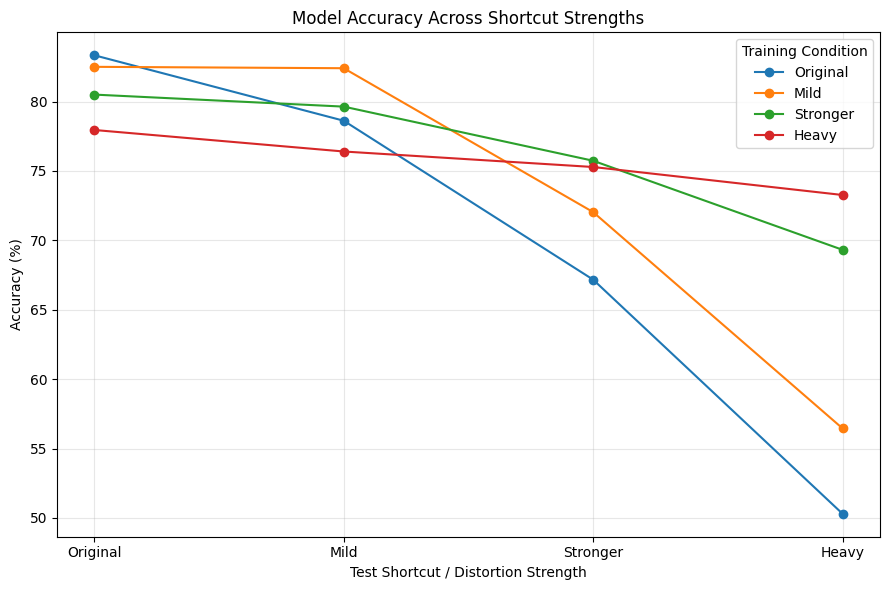

In [14]:
import matplotlib.pyplot as plt

strengths = ["Original", "Mild", "Stronger", "Heavy"]

plt.figure(figsize=(9, 6))

for _, row in comparison.iterrows():
    plt.plot(
        strengths,
        row[["Original Test", "Mild Test", "Stronger Test", "Heavy Test"]],
        marker="o",
        label=row["Model"]
    )

plt.xlabel("Test Shortcut / Distortion Strength")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Across Shortcut Strengths")
plt.legend(title="Training Condition")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
correct_indices = np.where(
    predicted_labels == test_labels
)[0][:5]

incorrect_indices = np.where(
    predicted_labels != test_labels
)[0][:5]

print("Correct indices:", correct_indices)
print("Incorrect indices:", incorrect_indices)

In [15]:
robustness = pd.DataFrame({
    "Model": ["Original", "Mild", "Stronger", "Heavy"],
    "Original Accuracy": [
        results["Original"]["test_run1_original"],
        results["Mild"]["test_run1_original"],
        results["Stronger"]["test_run1_original"],
        results["Heavy"]["test_run1_original"]
    ],
    "Heavy Accuracy": [
        results["Original"]["test_run4_heavy"],
        results["Mild"]["test_run4_heavy"],
        results["Stronger"]["test_run4_heavy"],
        results["Heavy"]["test_run4_heavy"]
    ]
})

robustness["Accuracy Drop"] = (
    robustness["Original Accuracy"] -
    robustness["Heavy Accuracy"]
)

robustness.iloc[:, 1:] = robustness.iloc[:, 1:] * 100

robustness

,Model,Original Accuracy,Heavy Accuracy,Accuracy Drop
0,Original,83.333331,50.300002,33.033329
1,Mild,82.499999,56.449997,26.050001
2,Stronger,80.500001,69.316667,11.183333
3,Heavy,77.950001,73.266667,4.683334


Week 3 Observation
The results show that stronger training conditions improve robustness to stronger distortions. The original model achieved the highest clean-data accuracy, but its performance dropped substantially as distortion strength increased. In contrast, the heavy-trained model had slightly lower clean-data accuracy but remained much more stable on stronger test conditions. This suggests a trade-off between clean-data performance and robustness, with stronger augmentation reducing sensitivity to distortion.

In [ ]:
fig, axes = plt.subplots(
    1,
    5,
    figsize=(12, 3)
)

for i, idx in enumerate(correct_indices):

    axes[i].imshow(test_images[idx])

    actual = ANIMAL_NAMES[
        test_labels[idx]
    ]

    predicted = ANIMAL_NAMES[
        predicted_labels[idx]
    ]

    confidence = predictions_prob[
        idx,
        predicted_labels[idx]
    ] * 100

    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"{confidence:.1f}%"
    )

    axes[i].axis("off")

plt.suptitle("5 Correct Predictions")
plt.tight_layout()
plt.show()

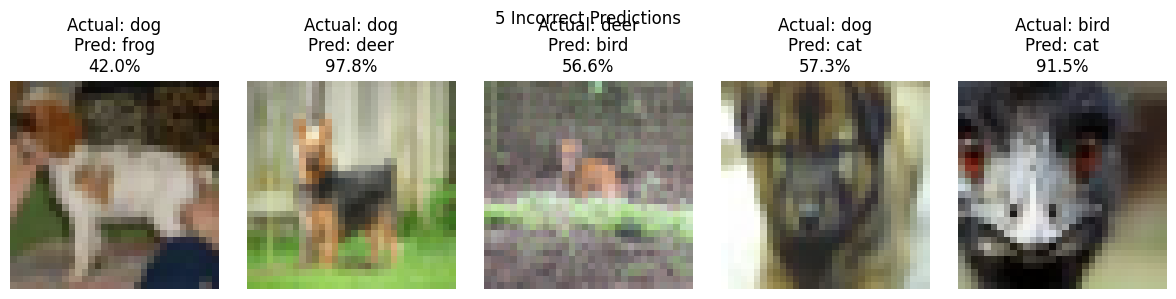

In [11]:
fig, axes = plt.subplots(
    1,
    5,
    figsize=(12, 3)
)

for i, idx in enumerate(incorrect_indices):

    axes[i].imshow(test_images[idx])

    actual = ANIMAL_NAMES[
        test_labels[idx]
    ]

    predicted = ANIMAL_NAMES[
        predicted_labels[idx]
    ]

    confidence = predictions_prob[
        idx,
        predicted_labels[idx]
    ] * 100

    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Pred: {predicted}\n"
        f"{confidence:.1f}%"
    )

    axes[i].axis("off")

plt.suptitle("5 Incorrect Predictions")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_labels,
    predicted_labels
)

print(cm)

[[675  39  48  22 126  90]
 [ 58 623  46  71 119  83]
 [ 56  47 666   1 138  92]
 [ 42 159  47 484 106 162]
 [ 34  36   5   2 913  10]
 [ 15  19  32   5  24 905]]


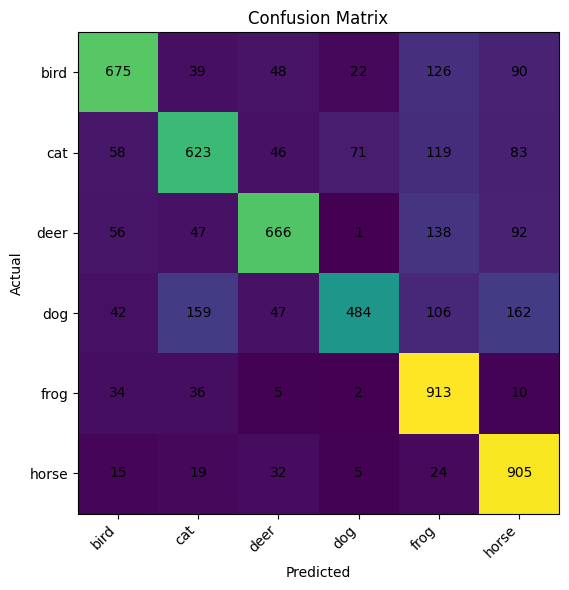

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(cm)

ax.set_xticks(
    np.arange(len(ANIMAL_NAMES))
)

ax.set_yticks(
    np.arange(len(ANIMAL_NAMES))
)

ax.set_xticklabels(
    ANIMAL_NAMES
)

ax.set_yticklabels(
    ANIMAL_NAMES
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right"
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix")

plt.tight_layout()
plt.show()

In [14]:
from sklearn.metrics import classification_report

print(
    classification_report(
        test_labels,
        predicted_labels,
        target_names=ANIMAL_NAMES
    )
)

              precision    recall  f1-score   support

        bird       0.77      0.68      0.72      1000
         cat       0.67      0.62      0.65      1000
        deer       0.79      0.67      0.72      1000
         dog       0.83      0.48      0.61      1000
        frog       0.64      0.91      0.75      1000
       horse       0.67      0.91      0.77      1000

    accuracy                           0.71      6000
   macro avg       0.73      0.71      0.70      6000
weighted avg       0.73      0.71      0.70      6000

